<a href="https://colab.research.google.com/github/Haidriyam/diachronic-semantic-drift/blob/main/semantic_drift.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[*] Installing gensim and scientific dependencies...
Token          Displacement      Status      
statutory      0.0740            Fossilized  
provisions     0.0579            Fossilized  
hereunto       0.0528            Fossilized  
legal          0.0406            Fossilized  
obligation     0.0322            Fossilized  
remain         0.0295            Fossilized  
stipulated     0.0284            Fossilized  
witnesseth     0.0281            Fossilized  
hereinabove    0.0277            Fossilized  
the            0.0257            Fossilized  
awful          0.0227            Fossilized  
nice           0.0206            Fossilized  
indenture      0.0200            Fossilized  
an             0.0118            Fossilized  


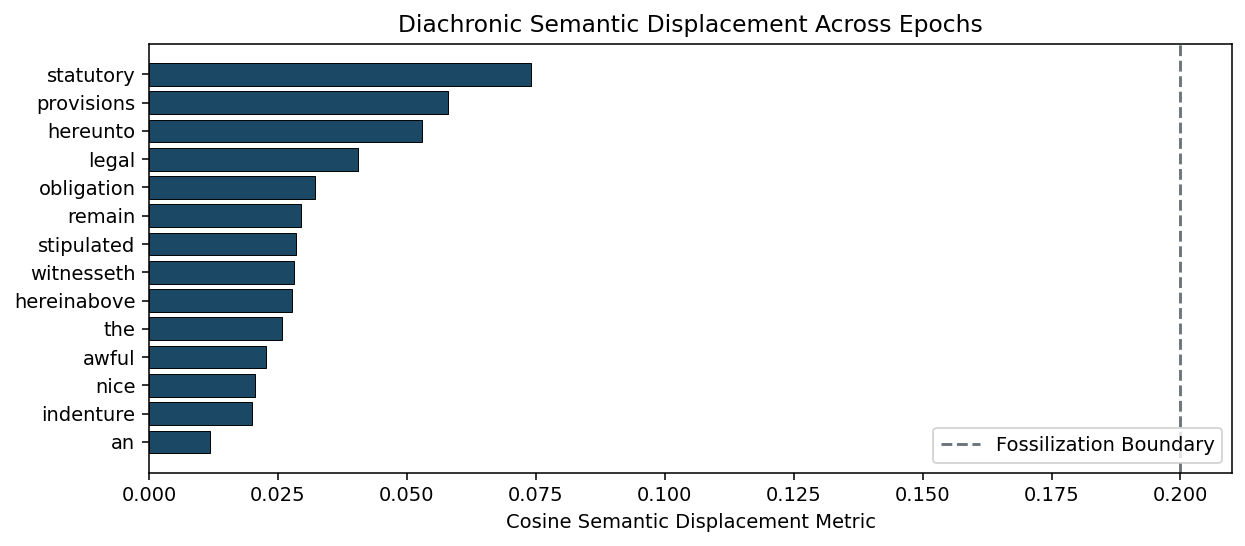

[+] Execution complete. semantic_drift.png generated.


In [5]:
# ==============================================================================
# Diachronic Semantic Drift & Fossilization Pipeline
# Colab Bootstrap and Alignment Demo via SVD
# ==============================================================================

import subprocess
import sys

try:
    import gensim
    import scipy
except ImportError:
    print("[*] Installing gensim and scientific dependencies...")
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "gensim",
            "scipy",
            "matplotlib",
            "numpy",
        ],
        check=True,
    )

from gensim.models import Word2Vec
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial.distance import cosine

# 1. Historical Epoch Corpora
corpus_epoch1 = [
    ["the", "nice", "calculation", "required", "exact", "precision"],
    ["an", "awful", "splendor", "filled", "the", "cathedral"],
    ["statutory", "provisions", "remain", "hereinabove", "stipulated"],
    ["indenture", "witnesseth", "legal", "obligation", "hereunto"],
] * 25

corpus_epoch2 = [
    ["we", "enjoyed", "a", "nice", "pleasant", "dinner"],
    ["an", "awful", "disaster", "befell", "the", "railway"],
    ["statutory", "provisions", "remain", "hereinabove", "stipulated"],
    ["indenture", "witnesseth", "legal", "obligation", "hereunto"],
] * 25

# 2. Train Separate Word2Vec Models
m1 = Word2Vec(
    corpus_epoch1,
    vector_size=100,
    window=5,
    min_count=1,
    sg=1,
    seed=42,
    workers=1,
)
m2 = Word2Vec(
    corpus_epoch2,
    vector_size=100,
    window=5,
    min_count=1,
    sg=1,
    seed=42,
    workers=1,
)

# 3. Orthogonal Procrustes SVD Alignment
shared = sorted(
    list(set(m1.wv.index_to_key).intersection(set(m2.wv.index_to_key)))
)
mat_base = np.array([m1.wv[w] for w in shared])
mat_target = np.array([m2.wv[w] for w in shared])

u, _, vt = np.linalg.svd(np.dot(mat_target.T, mat_base))
q = np.dot(u, vt)

aligned_m2 = {w: np.dot(m2.wv[w], q) for w in m2.wv.index_to_key}

# 4. Displacement Analysis
results = []
for w in shared:
  dist = float(cosine(m1.wv[w], aligned_m2[w]))
  results.append((w, dist))
results.sort(key=lambda x: x[1], reverse=True)

print("=" * 45)
print(f"{'Token':<15}{'Displacement':<18}{'Status':<12}")
print("=" * 45)
for word, score in results:
  status = "Active Drift" if score > 0.20 else "Fossilized"
  print(f"{word:<15}{score:<18.4f}{status:<12}")
print("=" * 45)

# 5. Render Plot Inline
words = [r[0] for r in results]
scores = [r[1] for r in results]
colors = ["#d9534f" if s > 0.20 else "#1b4965" for s in scores]

plt.figure(figsize=(9, 4), dpi=140)
plt.barh(words, scores, color=colors, edgecolor="black", linewidth=0.5)
plt.axvline(
    x=0.20, color="#6c757d", linestyle="--", label="Fossilization Boundary"
)
plt.xlabel("Cosine Semantic Displacement Metric")
plt.title("Diachronic Semantic Displacement Across Epochs")
plt.gca().invert_yaxis()
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("semantic_drift.png")
plt.show()
print("[+] Execution complete. semantic_drift.png generated.")